In [1]:
# Import all necessary libraries
import autograd
from autograd import jacobian
from autograd.misc.optimizers import adam
from autograd.scipy.integrate import odeint
import matplotlib.pyplot as plt
import pandas as pd
import autograd.numpy as np

In [2]:
# Building the Neural Network
# generate random number in the shape required to initialize the NN
'''def init_random_params(scale, layer_sizes, rs=np.random.RandomState(0)):
    """Build a list of (weights, biases) tuples,
       one for each layer in the net."""
    return [(scale * rs.randn(m, n),   # weight matrix
             scale * rs.randn(n))      # bias vector
            for m, n in zip(layer_sizes[:-1], layer_sizes[1:])]
''' # for future pytorch version. Let's follow tutuorial for now
np.random.seed(0)
def init_random_params(layer_sizes, scale):
    """Build a list of weights and biases, one for each layer in the net.
    layers is a list with the number of nodes in each layer. Minimum number of layers is three (input, hidden 
    and output) scale is a constant factor to scale the random values (down or up) if necessary"""
    params = []
    for i in range(len(layer_sizes) - 1):
        weight_matrix = layer_sizes[i]*layer_sizes[i + 1]
        bias_vector =layer_sizes[i + 1]
        params = np.append(params, np.random.rand(weight_matrix + bias_vector))
    return params*scale

def neural_net_predict(params, inputs):
    """Implements a (deep) neural network for regression.
       params is a list of weights and biases.
       inputs is a matrix of input values.
       returns network prediction."""
    # Make sure that params is a vector
    params = params.flatten()
    # set separator value for easier indexing of the parameters and assigning them to weights and biases 
    # for each layer
    sep = 0
    # loop over all layers
    for idx in range(len(layer_sizes)-1):
        # calculate weight matrix
        W = params[sep:sep+layer_sizes[idx]*layer_sizes[idx+1]].reshape(layer_sizes[idx],layer_sizes[idx+1])
        # calculate bias vector
        b = params[sep+layer_sizes[idx]*layer_sizes[idx+1]:sep+layer_sizes[idx]*layer_sizes[idx+1]
                   +layer_sizes[idx+1]]
        # set new separator value
        sep = layer_sizes[idx]*layer_sizes[idx+1]+layer_sizes[idx+1]
        # calculate output as weighted sum of inputs plus bias
        outputs = np.dot(inputs, W) + b
        # apply activation function and assign the result as the input to the next layer 
        # (note that this has no effect on the output layer)
        inputs = 1/(1 + np.exp(-outputs)) # Sigmoid activation
    return outputs    

In [3]:
init_random_params([3,3,1], 0.1)

array([0.05488135, 0.07151894, 0.06027634, 0.05448832, 0.04236548,
       0.06458941, 0.04375872, 0.0891773 , 0.09636628, 0.03834415,
       0.0791725 , 0.05288949, 0.05680446, 0.09255966, 0.00710361,
       0.00871293])

In [4]:
# Initialize the model parameters
# system parameters
tau = 100

# inlet concentrations
c_Ain = 0.7
c_Bin = 0.3
c_Xin = 0

# initial conditions for the concentrations in the reactor
c_A0 = 0.5
c_B0 = 0.5
c_X0 = 0

# end time for integration
t_end = 100
n_samples = 30
t_span = np.linspace(0, t_end, n_samples)

In [5]:
# implement the mechanistic part of the model
# define system equations
def dcdt(c, t, params):
    """Mechanistic part of the hybrid model (ODE system describing the time-dependent 
    concentrations in the reactor)"""
    # disassemble input vector
    c_A, c_B, c_X = c
    # calculate reaction rates by neural network prediction
    r = neural_net_predict(params, c)
    #r = 0.08*c_A**0.7*c_B**1.3 # true underlying reaction rate
    # system equations
    dcdt = [(c_Ain-c_A)/tau - r,
            (c_Bin-c_B)/tau - r,
            (c_Xin-c_X)/tau + r]
    return np.array(dcdt)

In [6]:
#  use the autograd package to calculate the jacobian with respect to the system states 
# and the parameters, which we’ll need for the sensitivity equations
# calculate system jacobian and parameter derivatives by automatic differentiation with autograd
dfdc = autograd.jacobian(dcdt, 0)    # system jacobian
dfdp = autograd.jacobian(dcdt, 2)    # parameter derivatives

In [7]:
def DiffEqs(y, t, params):
    """
    Right-hand side of the combined ODE system: the reactor mass balances plus
    the sensitivities of the concentrations to the network parameters.
    This is the function passed to odeint.

    Parameters
    ----------
    y : ndarray, shape (3 + 3*len_p,)
        State vector at time t.
        y[:3] = concentrations [C_A, C_B, C_X].
        y[3:] = sensitivities, in blocks of 3 per parameter:
                [dC_A/dw1, dC_B/dw1, dC_X/dw1, dC_A/dw2, ...].
    t : float
        Time. Not used explicitly, but odeint requires it.
    params : ndarray, shape (len_p,)
        Flat array of neural network weights and biases.

    Returns
    -------
    ndarray, shape (3 + 3*len_p,)
        Time derivative of y: [dC/dt (3 values), d(sensitivities)/dt (3*len_p values)].

    Notes
    -----
    Relies on the globals dcdt, dfdc, dfdp, len_p and len_c.
    For each parameter i: ds_i/dt = (df/dc) @ s_i + df/dw_i.
    """
    # disassemble input vector
    c = y[:3]
    s = y[3:]
     # evaluate system jacobian at current point
    dfdc_eval = dfdc(c, t, params)
    # evaluate parameter derivatives at current point
    dfdp_eval = dfdp(c, t, params) # Shape: (3, 1, 16)
 # define sensitivities for all parameters

    dcdp = np.zeros(len(s)) # preallocate memory for sensitivities
    for i in range(len_p):  # loop over all parameters to construct the corresponding sensitivity equations
        dcdp[i*len_c:(i+1)*len_c] = (dfdc_eval @ s[i*len_c:(i+1)*len_c]).flatten() + dfdp_eval[:,0,i] 
        # construct sensitivities 
        # [c1/w1, c2/w1, c3/w1, c1/w2, ...]
    return np.concatenate((dcdt(c, t, params).flatten(), dcdp))

In [8]:
# parameters for training the neural network

# Training parameters
scale = 0.0005
num_epochs = 1000
step_size = 0.001

# set neural network size
layer_sizes = [3, 3, 1] # no. of nodes in input layer, hidden layer(s) and output layer

# initialize parameter vector for neural network or load saved parameters
init_params = init_random_params(layer_sizes, scale)

In [9]:
# Specify initial value
# assemble initial value vector
c0 = [c_A0, c_B0, c_X0]
len_c = len(c0)
len_p = len(init_params)
s0 = np.zeros((len_p*len_c))
y0 = np.concatenate((c0,s0))

In [10]:
# import the data
df = pd.read_csv("../data/CSTR_ODE_data.txt", sep=';')
df.head()

,c_A,c_B,c_X
0,0.4959,0.5000,-0.0051
1,0.4470,0.4300,0.0579
2,0.4059,0.3880,0.1014
3,0.3854,0.3440,0.1410
4,0.3615,0.3093,0.1592


In [11]:
# changing into a numpy array for easier handling
c_exp = np.array(df)

In [12]:
def objective(params, iter):
    """
    Loss: sum of squared errors between predicted and measured concentrations.

    Parameters
    ----------
    params : ndarray, shape (len_p,)
        Flat array of neural network weights and biases.
    iter : int
        Iteration number. Not used, but the adam optimiser always passes it.

    Returns
    -------
    float
        Sum over all time points and all three species of
        (predicted concentration - measured concentration)**2.

    Notes
    -----
    Relies on the globals DiffEqs, y0, t_span and c_exp (shape: n_times x 3).
    With E = c_pred - c_exp, np.trace(E.T @ E) is the same as np.sum(E**2).
    There is no factor of 0.5 here. objective_grad returns the gradient of
    half of this value.
    """
    sol = odeint(DiffEqs, y0, t_span, args=(params,))
    # disassemble results
    c_pred = sol[:,:3] # predicted concentrations, just the columns corresponding to the concentrations, leave the sensitivities
    return np.trace((c_pred - c_exp).T @ (c_pred - c_exp))

In [13]:
def objective_grad(params, iter):
    """
    Gradient of the loss with respect to the network parameters,
    calculated from the sensitivities.

    Parameters
    ----------
    params : ndarray, shape (len_p,)
        Flat array of neural network weights and biases.
    iter : int
        Iteration number. Not used, but the adam optimiser always passes it.

    Returns
    -------
    ndarray, shape (len_p,)
        For each parameter j: the sum over all time points and all species of
        (predicted concentration - measured concentration) * sensitivity,
        where sensitivity = d(concentration)/d(parameter j).

    Notes
    -----
    Solves the combined ODE system once. Columns of sol:
    sol[:, :3] are the concentrations, sol[:, 3:] the sensitivities, ordered
    [dC_A/dw1, dC_B/dw1, dC_X/dw1, dC_A/dw2, ...].
    sens[:, k::3] picks species k for all parameters, shape (n_times, len_p).

    Relies on the globals DiffEqs, y0, t_span, c_exp, len_p and len_c.

    This is the gradient of 0.5 * sum((c_pred - c_exp)**2), that is, half of
    the gradient of the value returned by objective().
    """
    sol = odeint(DiffEqs, y0, t_span, args=(params,))
    # disassemble results
    c_pred = sol[:,:3] # predicted concentrations
    sens = sol[:,3:]   # sensititvities 16*3=48 -> c1/w1, c2/w1, c3/w1, c1/w2.....
    # calculate gradients of the loss function
    loss_grad = np.zeros(len_p) # set vector size
    for comp_idx in range(len_c):
        # For loop is running for each concentration and all parameters
        loss_grad += sens[:,comp_idx::3].T @ (c_pred[:,comp_idx] - c_exp[:,comp_idx])
    return loss_grad

In [14]:
def summary(params, iter, gradient):
    """Callback function gives informative output during optimization"""
    if iter % 10 == 0:
        print('step {0:5d}: {1:1.3e}'.format(iter, objective(params, iter)))
        np.save('Params', params)

In [15]:
# Optimize the network parameters
optimized_params = adam(objective_grad, init_params, step_size=step_size, num_iters=num_epochs, callback=summary)

step     0: 3.899e+00
step    10: 5.541e-01
step    20: 5.942e-01
step    30: 4.155e-01
step    40: 3.741e-01
step    50: 3.819e-01
step    60: 3.704e-01
step    70: 3.713e-01
step    80: 3.700e-01
step    90: 3.694e-01
step   100: 3.691e-01
step   110: 3.686e-01
step   120: 3.682e-01
step   130: 3.678e-01
step   140: 3.673e-01
step   150: 3.668e-01
step   160: 3.663e-01
step   170: 3.658e-01
step   180: 3.652e-01
step   190: 3.645e-01
step   200: 3.639e-01
step   210: 3.631e-01
step   220: 3.623e-01
step   230: 3.615e-01
step   240: 3.606e-01
step   250: 3.596e-01
step   260: 3.585e-01
step   270: 3.574e-01
step   280: 3.561e-01
step   290: 3.547e-01
step   300: 3.532e-01
step   310: 3.516e-01
step   320: 3.498e-01
step   330: 3.479e-01
step   340: 3.458e-01
step   350: 3.436e-01
step   360: 3.411e-01
step   370: 3.385e-01
step   380: 3.356e-01
step   390: 3.325e-01
step   400: 3.291e-01
step   410: 3.255e-01
step   420: 3.216e-01
step   430: 3.175e-01
step   440: 3.130e-01
step   450

In [16]:
sol_init = odeint(DiffEqs, y0, t_span, args=(init_params,))
sol_opt = odeint(DiffEqs, y0, t_span, args=(optimized_params,))

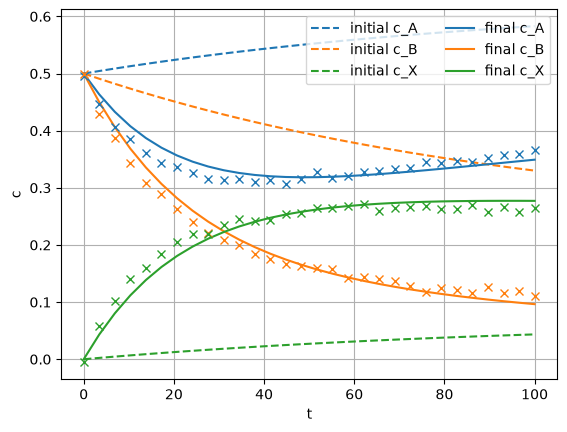

In [17]:
# plot system trajectories
plt.figure(1)
plt.plot(t_span, sol_init[:,:len_c],'--')
plt.gca().set_prop_cycle(None)
plt.plot(t_span, sol_opt[:,:len_c])
plt.gca().set_prop_cycle(None)
plt.plot(t_span, c_exp, 'x')
plt.xlabel('t')
plt.ylabel('c')
plt.legend(('initial c_A', 'initial c_B', 'initial c_X', 
            'final c_A', 'final c_B', 'final c_X'), loc='upper right',ncol=2) # make a legend
plt.grid()
plt.show()